In [5]:
import pandas as pd
import glob

data = pd.DataFrame()

csv_files = sorted(glob.glob("data_a/*.csv"))
csv_dfs = [pd.read_csv(p) for p in csv_files]

threads = [1, 16, 24, 32, 48, 64, 96, 128, 192]

for thr, df in zip(threads, csv_dfs):
  data["N"] = df["N"]
  data[f"Threads = {thr}"] = df["GFLOPS"]
  
data.head()

,N,Threads = 1,Threads = 16,Threads = 24,Threads = 32,Threads = 48,Threads = 64,Threads = 96,Threads = 128,Threads = 192
0,128,20.03,244.50,16.36,333.05,33.48,140.65,140.66,99.29,90.36
1,256,20.17,204.11,14.74,488.43,28.75,472.02,54.32,185.23,131.45
2,512,20.22,300.83,28.06,404.46,41.61,769.87,58.86,618.66,53.88
3,1024,18.53,297.83,33.19,532.91,43.37,680.22,75.68,856.37,80.41
4,2048,8.06,319.96,39.90,595.67,53.64,900.47,88.89,796.02,120.35


Text(0, 0.5, 'GB/s')

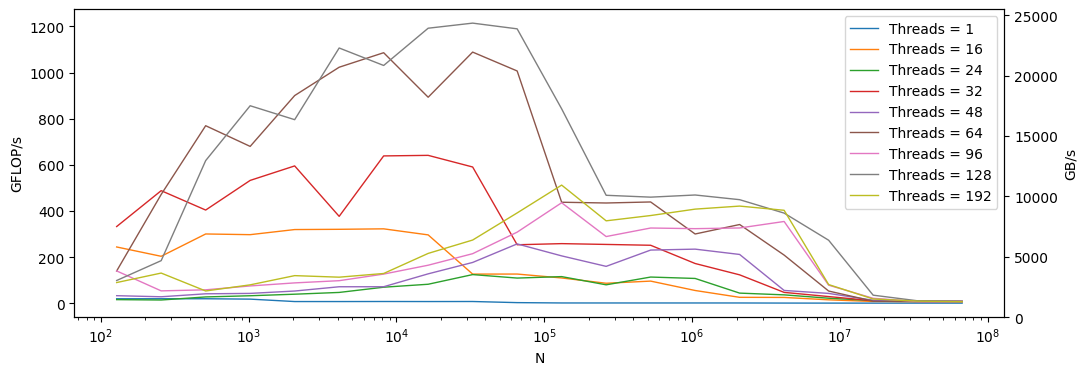

In [6]:

ax = data.plot(x="N", linewidth=1, figsize=(12, 4))
ax.set_ylabel("GFLOP/s")
ax.set_xscale("log")

ax2 = ax.twinx()
ax2.set_ylim(0, ax.get_ylim()[1] * 20)
ax2.set_ylabel("GB/s")


In [3]:
data = pd.DataFrame()

csv_files = sorted(glob.glob("data_b/*.csv"))
csv_dfs = [pd.read_csv(p) for p in csv_files]

modes = ["Thread Pinning = Close", "Thread Pinning = Spread, No parallel initialization", "Thread Pinning = Spread, Parallel initialization"]

for mode, df in zip(modes, csv_dfs):
  data["Threads"] = df["Threads"]
  data[mode] = df["GFLOPS"]
  
data.head()

,Threads,Thread Pinning = Close,"Thread Pinning = Spread, No parallel initialization","Thread Pinning = Spread, Parallel initialization"
0,1,1.19,1.19,1.19
1,2,1.27,1.33,2.40
2,4,2.43,2.29,4.69
3,8,3.84,3.07,7.46
4,16,3.85,3.31,7.79


Text(0, 0.5, 'GB/s')

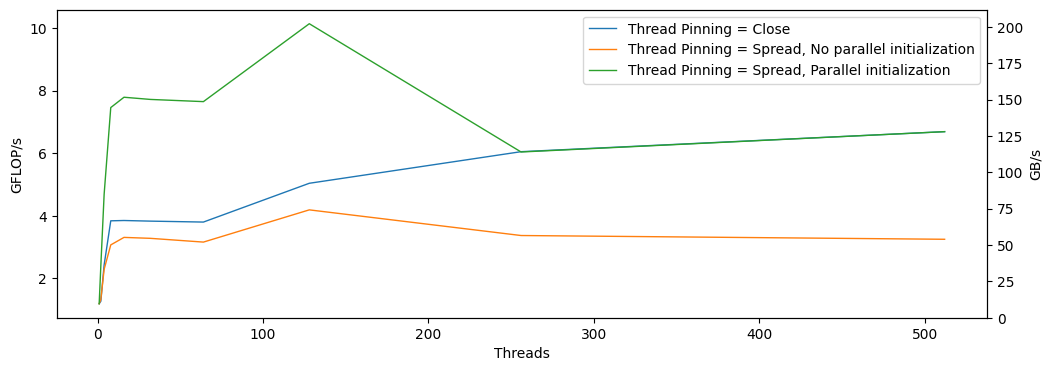

In [4]:
ax = data.plot(x="Threads", linewidth=1, figsize=(12, 4))
ax.set_ylabel("GFLOP/s")

ax2 = ax.twinx()
ax2.set_ylim(0, ax.get_ylim()[1] * 20)
ax2.set_ylabel("GB/s")